# 01 · Data analysis: latency of FP32 vs INT8 GNN inference under growing load

**Project:** Zero-Day Attack Detection in IoT Networks via GNNs (Task 3, Weeks 7–9).
**Goal:** turn the raw benchmark log `data/raw/test_run.jsonl` into cleaned, aggregated metrics
(`data/processed/metrics_summary.csv`) and two publication-ready figures.

| Role | Model | Meaning |
|---|---|---|
| Baseline | `gnn_fp32` | 2-hop propagation + FP32 linear head |
| Proposed | `gnn_int8` | same propagation + symmetric INT8 quantized head (H1) |
| Reference | `flat_lr` | non-graph logistic regression (H2 baseline) |

**Independent variable (load):** number of flows scored in one inference call (250 … 8000).
**Dependent variables:** inference latency (ms), throughput (flows/s). **Guardrail metrics:** classification error rate, FPR, precision, F1 drop vs FP32.

> ⚠️ **Data provenance.** Latencies are *real timings* of this repository's code (`src/graph_builder.py`, `src/models.py`).
> The flow table is a **seeded synthetic stream** (`src/collect_runs.py`), because the full BoT-IoT subset is not committed.
> Therefore detection metrics here only verify the pipeline and are **not** scientific detection results.

## 0. Setup and reproducibility
All randomness (data generation, bootstrap) uses fixed seed **42**.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
np.random.seed(SEED)                      # global seed (bootstrap uses its own seeded Generator as well)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import process_data as pdp
import visualize as viz

RAW = ROOT / "data/raw/test_run.jsonl"
PROCESSED = ROOT / "data/processed/metrics_summary.csv"
FIG_DIR = ROOT / "reports/figures"
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
print("project root :", ROOT.name)
print("seed         :", SEED, "| bootstrap resamples:", pdp.N_BOOT, "| CI level:", pdp.CI_LEVEL)

project root : iot-gnn-zeroday-benchmark
seed         : 42 | bootstrap resamples: 5000 | CI level: 0.95


## 1. Data ingestion & warm-up filtering
Every inference call is one JSON line. The first `WARMUP = 5` calls of every (fold × model × load)
configuration are tagged `phase = "warmup"` (CPU caches, BLAS initialisation, lazy allocations) and must not enter the statistics.

In [2]:
raw = pdp.load_jsonl(RAW)
print("records:", len(raw), "| columns:", list(raw.columns))
print()
print(raw.groupby("phase").size().rename("calls").to_frame())
raw.head()

records: 1890 | columns: ['model', 'fold', 'load_flows', 'run', 'phase', 'latency_ms', 'throughput_flows_s', 'n_errors', 'error_rate', 'fpr', 'precision', 'recall']

        calls
phase        
eval     1620
warmup    270


,model,fold,load_flows,run,phase,latency_ms,throughput_flows_s,n_errors,error_rate,fpr,precision,recall
0,flat_lr,dos_syn,250,0,warmup,0.37373,668939.28,11,0.044,0.028409,0.931507,0.918919
1,flat_lr,dos_syn,250,1,warmup,0.30747,813084.81,11,0.044,0.028409,0.931507,0.918919
2,flat_lr,dos_syn,250,2,warmup,0.21796,1146988.92,11,0.044,0.028409,0.931507,0.918919
3,flat_lr,dos_syn,250,3,warmup,0.24616,1015603.74,11,0.044,0.028409,0.931507,0.918919
4,flat_lr,dos_syn,250,4,warmup,0.18177,1375394.74,11,0.044,0.028409,0.931507,0.918919


run
0    1.645
1    1.177
2    1.072
3    1.040
4    1.007
5    1.002
6    1.010
7    1.011


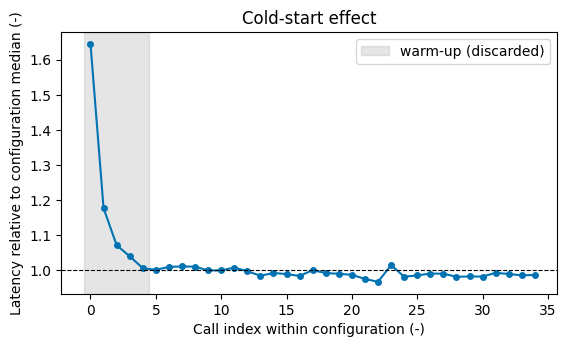

In [3]:
# Evidence for the cold-start effect: median latency by call index inside a configuration (all configs, load-normalised)
raw["lat_rel"] = raw["latency_ms"] / raw.groupby(["fold", "model", "load_flows"])["latency_ms"].transform("median")
by_run = raw.groupby("run")["lat_rel"].median()
fig_w, ax_w = plt.subplots(figsize=(6.4, 3.4))
ax_w.plot(by_run.index, by_run.values, color=viz._PAL[0], marker="o", linestyle="-", markersize=4)
ax_w.axvspan(-0.5, 4.5, color="grey", alpha=0.2, label="warm-up (discarded)")
ax_w.axhline(1.0, color="black", linestyle="--", linewidth=0.8)
ax_w.set_xlabel("Call index within configuration (-)")
ax_w.set_ylabel("Latency relative to configuration median (-)")
ax_w.set_title("Cold-start effect"); ax_w.legend()
print(by_run.head(8).round(3).to_string())

In [4]:
eval_df = pdp.filter_warmup(raw)
print(f"discarded warm-up calls: {len(raw) - len(eval_df)}  |  kept evaluation calls: {len(eval_df)}")
print("calls per (model, load):", eval_df.groupby(["model", "load_flows"]).size().unique())

discarded warm-up calls: 270  |  kept evaluation calls: 1620
calls per (model, load): [90]


## 2. Statistical aggregation
For every (model, load) we report median, quartiles (p25–p75), p95, p99, mean ± SD and a **percentile-bootstrap 95 % CI of the median**
(5000 resamples, seeded). Latencies are pooled over the 3 leave-one-attack-out folds × 30 evaluation calls = 90 calls per cell.

In [5]:
summary = pdp.aggregate(eval_df)
PROCESSED.parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(PROCESSED, index=False, float_format="%.6g")
cols = ["model", "load_flows", "lat_n", "lat_median", "lat_p25", "lat_p75", "lat_p95", "lat_p99", "lat_mean", "lat_sd", "lat_ci95_lo", "lat_ci95_hi"]
print("saved:", PROCESSED.relative_to(ROOT), "| shape:", summary.shape)
summary[cols].round(4)

saved: data/processed/metrics_summary.csv | shape: (18, 19)


,model,load_flows,lat_n,lat_median,lat_p25,lat_p75,lat_p95,lat_p99,lat_mean,lat_sd,lat_ci95_lo,lat_ci95_hi
0,flat_lr,250,90,0.1137,0.1062,0.1547,0.2025,0.2120,0.1326,0.0329,0.1098,0.1352
1,flat_lr,500,90,0.1210,0.1090,0.1541,0.2038,0.2278,0.1360,0.0327,0.1136,0.1446
2,flat_lr,1000,90,0.1281,0.1120,0.1649,0.2158,0.2524,0.1427,0.0373,0.1179,0.1453
3,flat_lr,2000,90,0.1213,0.1161,0.1333,0.1812,0.2314,0.1306,0.0264,0.1182,0.1242
4,flat_lr,4000,90,0.1316,0.1266,0.1422,0.1751,0.2422,0.1399,0.0245,0.1290,0.1345
5,flat_lr,8000,90,0.1422,0.1362,0.1595,0.1971,0.2468,0.1524,0.0252,0.1397,0.1477
6,gnn_fp32,250,90,0.1479,0.1408,0.1554,0.2244,0.3517,0.1591,0.0375,0.1455,0.1497
7,gnn_fp32,500,90,0.3040,0.2835,0.3332,0.4211,0.5664,0.3186,0.0588,0.2961,0.3162
8,gnn_fp32,1000,90,0.8724,0.8414,0.9078,0.9833,1.0073,0.8750,0.0585,0.8626,0.8852
9,gnn_fp32,2000,90,1.5845,1.5324,1.6318,1.7164,1.8710,1.5910,0.0939,1.5663,1.5958


In [6]:
# Throughput (flows/s) with bootstrap CI
summary[["model", "load_flows", "thr_median", "thr_ci95_lo", "thr_ci95_hi"]].round(0).astype({"thr_median": int, "thr_ci95_lo": int, "thr_ci95_hi": int})

,model,load_flows,thr_median,thr_ci95_lo,thr_ci95_hi
0,flat_lr,250,2198363,1849578,2276815
1,flat_lr,500,4134869,3457239,4401455
2,flat_lr,1000,7807895,6887523,8480529
3,flat_lr,2000,16487632,16099420,16923523
4,flat_lr,4000,30393652,29741917,31007994
5,flat_lr,8000,56257012,54160183,57281847
6,gnn_fp32,250,1690446,1670420,1718851
7,gnn_fp32,500,1644934,1581364,1688881
8,gnn_fp32,1000,1146194,1129717,1159253
9,gnn_fp32,2000,1262235,1253273,1276889


### 2.1 Hypothesis H1 check: latency ratio INT8 / FP32
H1 requires median latency reduction ≥ 30 %, i.e. the **upper limit of the 95 % bootstrap CI of the ratio must be < 0.70**.

In [7]:
ratio = pdp.latency_ratio_table(eval_df)
ratio.round(3)

,load_flows,ratio,ci95_lo,ci95_hi,h1_latency_ok
0,250,0.299,0.280,0.360,True
1,500,0.696,0.633,0.734,False
2,1000,0.852,0.836,0.899,False
3,2000,0.921,0.909,0.938,False
4,4000,0.953,0.939,0.974,False
5,8000,0.977,0.958,0.991,False


### 2.2 Guardrail metrics (error rate, FPR, precision, F1 drop)
Error rate = share of misclassified flows in a scored batch (1 − accuracy). H1 guardrails: precision ≥ 0.92 and F1 drop vs FP32 ≤ 0.02.

In [8]:
guard = pdp.guardrail_table(eval_df)
guard.round(4)

,model,error_rate,fpr,precision,recall,f1,f1_drop_vs_fp32,guardrail
0,flat_lr,0.1084,0.0132,0.6359,0.6168,0.6261,0.3672,FAIL
1,gnn_fp32,0.0036,0.0012,0.9970,0.9898,0.9933,0.0000,reference
2,gnn_int8,0.0034,0.0009,0.9976,0.9898,0.9936,-0.0003,pass


## 3. Visualization & export
Both figures are written to `reports/figures/` as vector **PDF** and **PNG at 300 DPI**.

['/content/iot-gnn-zeroday-benchmark/reports/figures/fig1_latency_vs_load.pdf', '/content/iot-gnn-zeroday-benchmark/reports/figures/fig1_latency_vs_load.png']


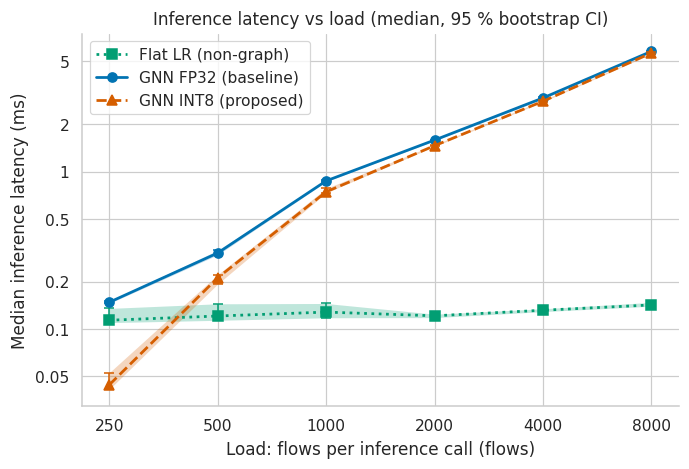

In [9]:
fig1 = viz.plot_latency_vs_load(summary)
print(viz.save_figure(fig1, "fig1_latency_vs_load", str(FIG_DIR)))

['/content/iot-gnn-zeroday-benchmark/reports/figures/fig2_distribution_boxplot.pdf', '/content/iot-gnn-zeroday-benchmark/reports/figures/fig2_distribution_boxplot.png']


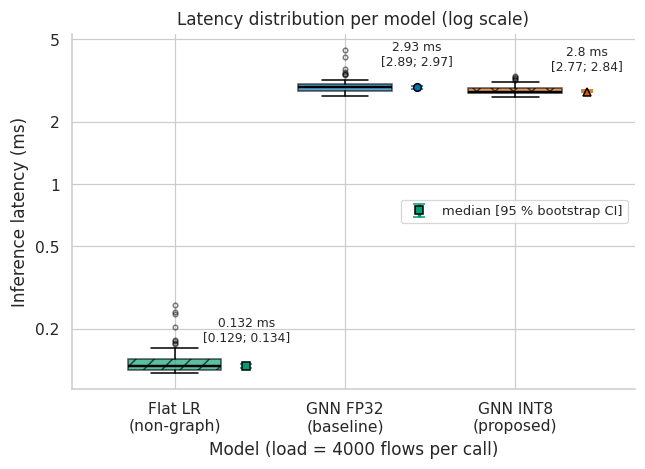

In [10]:
fig2 = viz.plot_distribution_boxplot(eval_df, load=4000)
print(viz.save_figure(fig2, "fig2_distribution_boxplot", str(FIG_DIR)))

In [11]:
# Export check: both formats exist, PNG resolution >= 300 DPI
rows = []
for stem in ("fig1_latency_vs_load", "fig2_distribution_boxplot"):
    for ext in ("pdf", "png"):
        p = FIG_DIR / f"{stem}.{ext}"
        dpi = round(Image.open(p).info["dpi"][0]) if ext == "png" else "vector"
        rows.append({"file": f"reports/figures/{stem}.{ext}", "size_kB": round(p.stat().st_size / 1024, 1), "dpi": dpi})
check = pd.DataFrame(rows); print(check.to_string(index=False))
assert all(r["dpi"] == "vector" or r["dpi"] >= 300 for r in rows)

                                         file  size_kB    dpi
     reports/figures/fig1_latency_vs_load.pdf     16.2 vector
     reports/figures/fig1_latency_vs_load.png    191.2    300
reports/figures/fig2_distribution_boxplot.pdf     17.4 vector
reports/figures/fig2_distribution_boxplot.png    132.1    300


## 4. Summary table for the README (Baseline vs Proposed)

In [12]:
table_md = pdp.readme_table(summary, ratio)
print(table_md)

| Load (flows/call) | Method | Median (p25–p75), ms | Mean ± SD, ms | p95, ms | p99, ms | Median 95 % CI, ms | INT8/FP32 ratio [95 % CI] |
|---:|:---|:---|:---|---:|---:|:---|:---|
| 250 | Baseline (GNN FP32) | 0.148 (0.141-0.155) | 0.159 ± 0.037 | 0.224 | 0.352 | [0.145; 0.150] | – |
| 250 | Proposed (GNN INT8) | 0.044 (0.040-0.065) | 0.058 ± 0.029 | 0.110 | 0.138 | [0.041; 0.053] | 0.30 [0.28; 0.36] |
| 500 | Baseline (GNN FP32) | 0.304 (0.283-0.333) | 0.319 ± 0.059 | 0.421 | 0.566 | [0.296; 0.316] | – |
| 500 | Proposed (GNN INT8) | 0.212 (0.183-0.264) | 0.223 ± 0.047 | 0.303 | 0.323 | [0.193; 0.222] | 0.70 [0.63; 0.73] |
| 1000 | Baseline (GNN FP32) | 0.872 (0.841-0.908) | 0.875 ± 0.058 | 0.983 | 1.007 | [0.863; 0.885] | – |
| 1000 | Proposed (GNN INT8) | 0.743 (0.712-0.941) | 0.810 ± 0.122 | 1.001 | 1.059 | [0.733; 0.782] | 0.85 [0.84; 0.90] |
| 2000 | Baseline (GNN FP32) | 1.584 (1.532-1.632) | 1.591 ± 0.094 | 1.716 | 1.871 | [1.566; 1.596] | – |
| 2000 | Proposed (GNN INT8) | 1.

## 5. Discussion

* **Warm-up matters.** The first call of a configuration is ≈1.6× slower than steady state and the second ≈1.2×; from the 6th call on the relative latency is ≈1.0 (§1). Dropping the 5 warm-up calls removes this bias (270 of 1890 calls discarded).
* **Latency scales with load for graph models, not for the flat model.** `gnn_fp32` grows from ≈0.15 ms (250 flows) to ≈5.8 ms (8000 flows), roughly linear in the number of 1000-flow windows, because the dense `A_norm @ H` products dominate. `flat_lr` stays at ≈0.11–0.14 ms (no propagation). Both axes are logarithmic because the values span >1.5 orders of magnitude.
* **H1 (INT8 vs FP32 latency, ratio upper CI < 0.70) is supported only at the smallest load.** At 250 flows the ratio is 0.30 [0.28; 0.36]; at 500 flows the upper limit is 0.73 (not met), and from 1000 flows on the ratio is 0.85–0.98. Reason: in this skeleton only the *head* is quantized, propagation stays FP32. The large gain at 250 flows is mostly Python/sklearn call overhead (`LogisticRegression.predict` input validation) that the hand-written INT8 predictor avoids — it is **not** evidence of faster integer arithmetic. Real INT8 gains require quantized propagation (planned in Week 7+).
* **Guardrails.** INT8 keeps precision (≥ 0.92) and F1 within 0.02 of FP32 (difference −0.0003), so the guardrail passes; error rate 0.34 % vs 0.36 %. `flat_lr` fails the guardrail, mostly because it detects none of the unseen `port_scan` flows (precision = recall = 0 in that fold) — consistent in direction with H2, but see the caveat below.
* **Caveats.** (i) Flow data are synthetic, so detection metrics are pipeline checks only. (ii) Timings come from a shared 2-vCPU cloud machine (BLAS threads = 1), not from the `--cpus=1 --memory=512m` Docker edge profile; absolute values will differ on the target hardware, so re-run `python src/collect_runs.py` there. (iii) Models run in a fixed order per configuration, so cache-state differences cannot be fully excluded. (iv) The 3 folds × 30 calls are not independent samples of a hardware population; the CI quantifies run-to-run timing noise only.